<a href="https://colab.research.google.com/github/narayn02/Codealpha_tasks/blob/main/Iris_Flower_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **IRIS FLOWER CLASSIFICATION**

In [1]:
# CodeAlpha - Iris Flower Classification
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.datasets import load_iris
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.inspection import permutation_importance

import joblib
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")

print("Libraries imported successfully!")
print("Scikit-learn version:", sklearn.__version__)

Libraries imported successfully!
Scikit-learn version: 1.6.1


In [7]:
from google.colab import files
uploaded = files.upload()

Saving Iris.csv to Iris.csv


In [8]:
df = pd.read_csv("Iris.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (150, 6)


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [9]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe().round(2))

print("\nFirst five records:")
display(df.head())

Column names:
['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB

Statistical summary:


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.00,150.00,150.00,150.00,150.00
mean,75.50,5.84,3.05,3.76,1.20
std,43.45,0.83,0.43,1.76,0.76
min,1.00,4.30,2.00,1.00,0.10
25%,38.25,5.10,2.80,1.60,0.30
50%,75.50,5.80,3.00,4.35,1.30
75%,112.75,6.40,3.30,5.10,1.80
max,150.00,7.90,4.40,6.90,2.50



First five records:


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


### **CHECK MISSING AND DUPLICATE VALUES**

In [10]:
print("Missing values in each column:")
display(df.isnull().sum())

print("Total missing values:", df.isnull().sum().sum())

print("Duplicate complete rows:", df.duplicated().sum())

print("\nSpecies distribution:")
display(df["Species"].value_counts())

print("\nUnique species:")
print(df["Species"].unique())

Missing values in each column:


,0
Id,0
SepalLengthCm,0
SepalWidthCm,0
PetalLengthCm,0
PetalWidthCm,0
Species,0


Total missing values: 0
Duplicate complete rows: 0

Species distribution:


,count
Species,
Iris-setosa,50
Iris-versicolor,50
Iris-virginica,50



Unique species:
['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']


VISUALISE SPECIES DISTRIBUTION

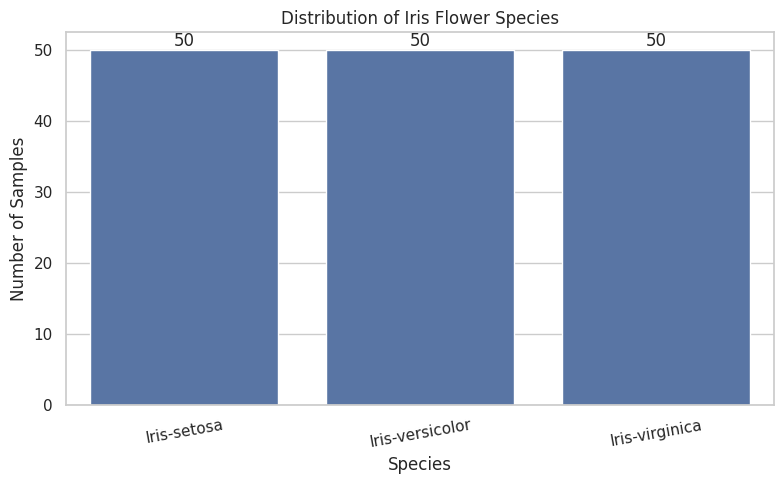

In [11]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="Species",
    order=sorted(df["Species"].unique())
)

ax.bar_label(ax.containers[0])

plt.title("Distribution of Iris Flower Species")
plt.xlabel("Species")
plt.ylabel("Number of Samples")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

VISUALISE FEATURE DISTRIBUTIONS

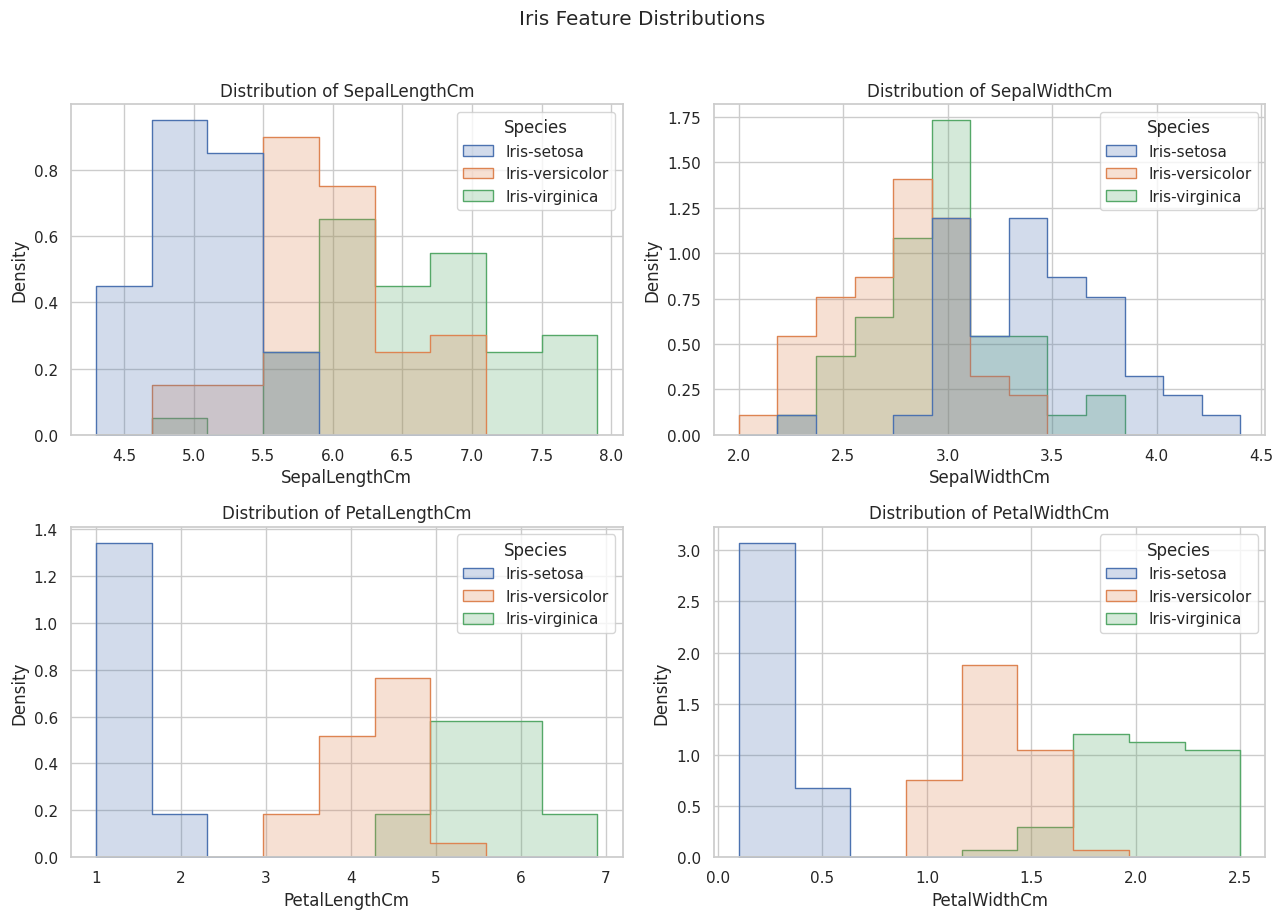

In [12]:
feature_names = [
    "SepalLengthCm",
    "SepalWidthCm",
    "PetalLengthCm",
    "PetalWidthCm"
]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for column, ax in zip(feature_names, axes.flatten()):
    sns.histplot(
        data=df,
        x=column,
        hue="Species",
        element="step",
        stat="density",
        common_norm=False,
        ax=ax
    )

    ax.set_title(f"Distribution of {column}")

plt.suptitle("Iris Feature Distributions", y=1.02)
plt.tight_layout()
plt.show()

PAIRPLOT VISUALIZATION

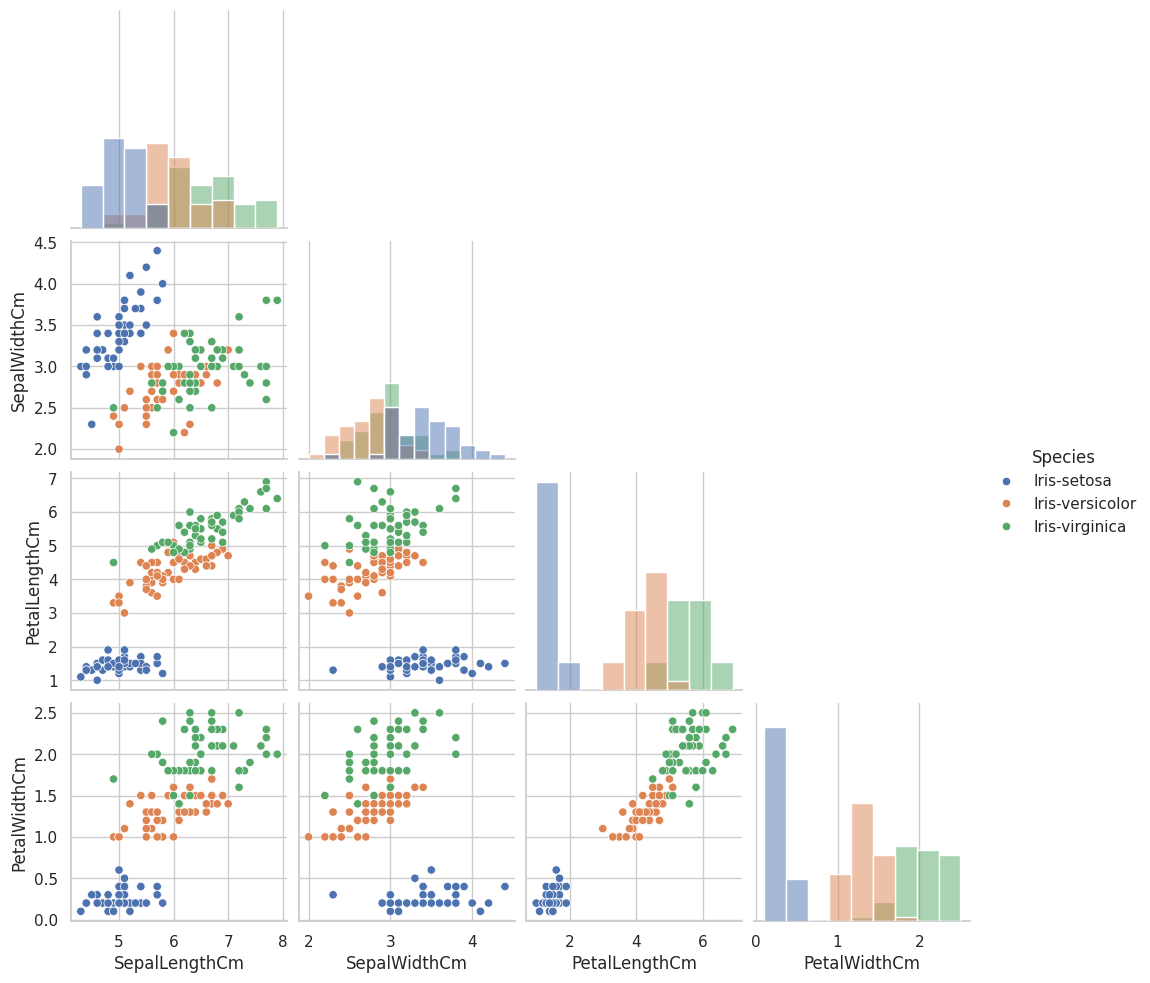

In [13]:
sns.pairplot(
    df[feature_names + ["Species"]],
    hue="Species",
    diag_kind="hist",
    corner=True
)

plt.show()

CORRELATION HEATMAP

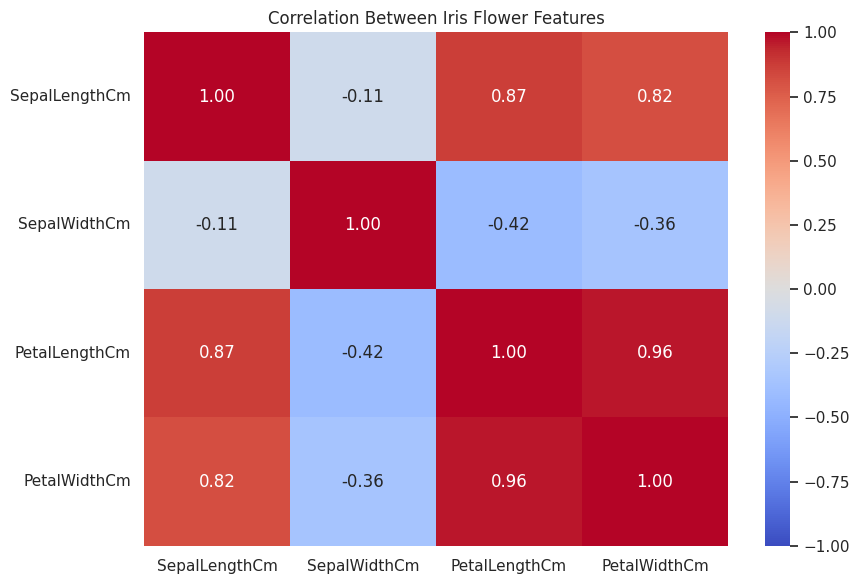

In [14]:
plt.figure(figsize=(9, 6))

correlation = df[feature_names].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation Between Iris Flower Features")
plt.tight_layout()
plt.show()

PREPARE THE INPUT FEATURES AND TARGET

In [15]:
X = df[feature_names].copy()
y = df["Species"].copy()

print("Input features:")
display(X.head())

print("\nTarget variable:")
display(y.head())

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

Input features:


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2



Target variable:


,Species
0,Iris-setosa
1,Iris-setosa
2,Iris-setosa
3,Iris-setosa
4,Iris-setosa



Feature shape: (150, 4)
Target shape: (150,)


SPLIT AND TRAIN-TEST

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining species distribution:")
display(y_train.value_counts())

print("\nTesting species distribution:")
display(y_test.value_counts())

Training samples: 120
Testing samples: 30

Training species distribution:


,count
Species,
Iris-setosa,40
Iris-virginica,40
Iris-versicolor,40



Testing species distribution:


,count
Species,
Iris-setosa,10
Iris-virginica,10
Iris-versicolor,10


DEFINE M.L MODELS

In [17]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000))
    ]),

    "K-Nearest Neighbors": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier())
    ]),

    "Decision Tree": Pipeline([
        ("model", DecisionTreeClassifier(random_state=42))
    ]),

    "Random Forest": Pipeline([
        ("model", RandomForestClassifier(
            n_estimators=200,
            random_state=42
        ))
    ]),

    "Support Vector Machine": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC())
    ])
}

print("Models created successfully:")
for name in models:
    print("-", name)

Models created successfully:
- Logistic Regression
- K-Nearest Neighbors
- Decision Tree
- Random Forest
- Support Vector Machine


COMPARE MODEL USING CROSS VALIDATION

In [18]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for name, model in models.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy"
    )

    results.append({
        "Model": name,
        "Mean CV Accuracy": scores.mean(),
        "CV Standard Deviation": scores.std()
    })

cv_results = pd.DataFrame(results)

cv_results = cv_results.sort_values(
    by="Mean CV Accuracy",
    ascending=False
).reset_index(drop=True)

display(cv_results.round(4))

,Model,Mean CV Accuracy,CV Standard Deviation
0,Support Vector Machine,0.9667,0.0167
1,Logistic Regression,0.9583,0.0264
2,K-Nearest Neighbors,0.9583,0.0264
3,Decision Tree,0.9500,0.0167
4,Random Forest,0.9500,0.0312


PLOT MODEL COMPARISION

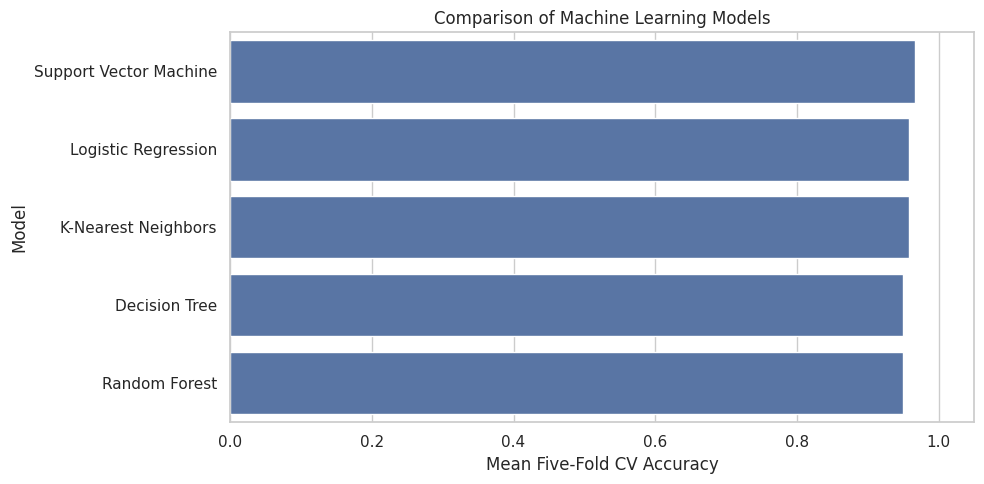

In [19]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=cv_results,
    x="Mean CV Accuracy",
    y="Model"
)

plt.xlim(0, 1.05)
plt.title("Comparison of Machine Learning Models")
plt.xlabel("Mean Five-Fold CV Accuracy")
plt.ylabel("Model")
plt.tight_layout()
plt.show()

In [20]:
best_model_name = cv_results.iloc[0]["Model"]
best_model = models[best_model_name]

best_model.fit(X_train, y_train)

print("Selected model:", best_model_name)
print("Model trained successfully!")

Selected model: Support Vector Machine
Model trained successfully!


EVALUATE THE MODEL ON TEST DATA

In [21]:
y_pred = best_model.predict(X_test)

test_accuracy = accuracy_score(y_test, y_pred)

test_precision = precision_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

test_recall = recall_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

test_f1 = f1_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

print("Selected model:", best_model_name)
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Macro Precision: {test_precision:.4f}")
print(f"Macro Recall: {test_recall:.4f}")
print(f"Macro F1-score: {test_f1:.4f}")

Selected model: Support Vector Machine
Test Accuracy: 0.9667
Macro Precision: 0.9697
Macro Recall: 0.9667
Macro F1-score: 0.9666


CLASSIFICATION REPORT

In [22]:
species_names = sorted(y.unique())

print(
    classification_report(
        y_test,
        y_pred,
        labels=species_names,
        target_names=species_names,
        zero_division=0
    )
)

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



CONFUSION MATRIX

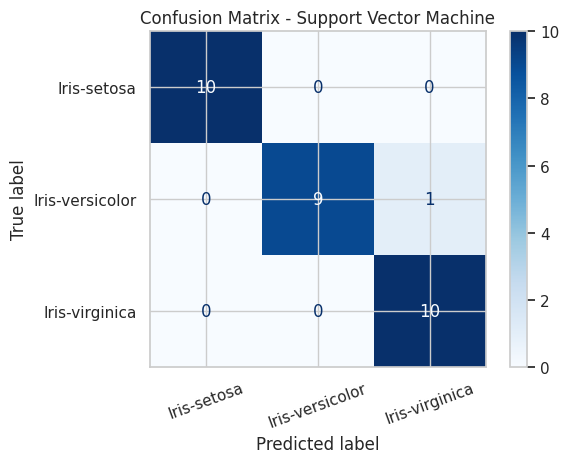

In [23]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=species_names,
    display_labels=species_names,
    cmap="Blues",
    values_format="d",
    xticks_rotation=20
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

,Feature,Importance,Standard Deviation
0,PetalWidthCm,0.2811,0.0744
1,PetalLengthCm,0.2267,0.0635
2,SepalWidthCm,0.0522,0.0410
3,SepalLengthCm,0.0033,0.0100


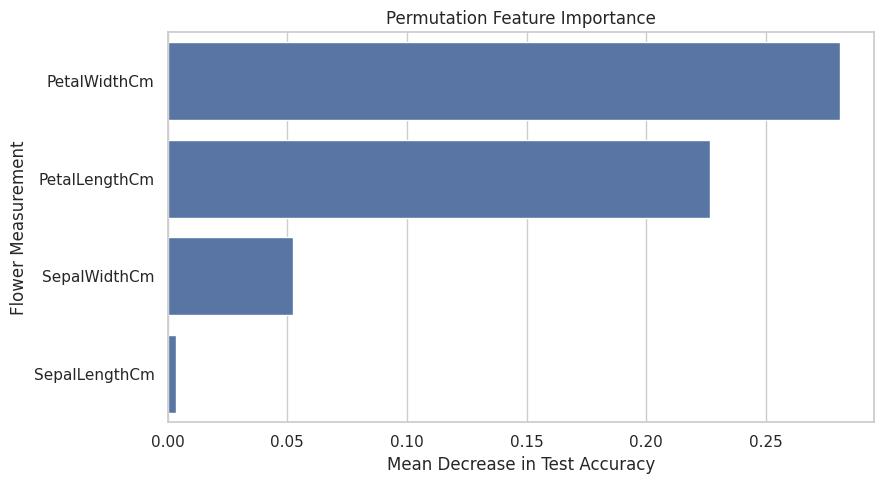

In [24]:
perm = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="accuracy",
    n_repeats=30,
    random_state=42
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": perm.importances_mean,
    "Standard Deviation": perm.importances_std
}).sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

display(importance_df.round(4))

plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Permutation Feature Importance")
plt.xlabel("Mean Decrease in Test Accuracy")
plt.ylabel("Flower Measurement")
plt.tight_layout()
plt.show()

PREDICT A NEW FLOWER

In [25]:
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=feature_names
)

prediction = best_model.predict(new_flower)[0]

print("New flower measurements:")
display(new_flower)

print("Predicted species:", prediction)

if hasattr(best_model, "predict_proba"):
    probabilities = best_model.predict_proba(new_flower)[0]

    probability_df = pd.DataFrame({
        "Species": best_model.classes_,
        "Model Score": probabilities
    }).sort_values(
        by="Model Score",
        ascending=False
    )

    display(probability_df.round(4))

New flower measurements:


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2


Predicted species: Iris-setosa


SAVE THE TRAINED MODEL

In [26]:
model_filename = "iris_best_model.joblib"

model_artifact = {
    "model": best_model,
    "model_name": best_model_name,
    "feature_names": feature_names,
    "species_names": species_names
}

joblib.dump(model_artifact, model_filename)

print("Model saved successfully:", model_filename)

Model saved successfully: iris_best_model.joblib


RELOAD THE MODEL AND EXPORT RESULTS

In [27]:
saved_artifact = joblib.load("iris_best_model.joblib")

loaded_model = saved_artifact["model"]
loaded_prediction = loaded_model.predict(new_flower)[0]

print("Prediction before saving:", prediction)
print("Prediction after loading:", loaded_prediction)

assert prediction == loaded_prediction, "Prediction mismatch!"

print("\nModel verification successful!")


df.to_csv("iris_dataset.csv", index=False)
cv_results.to_csv("model_comparison.csv", index=False)
importance_df.to_csv("feature_importance.csv", index=False)

print("\nFiles exported:")
print("- iris_dataset.csv")
print("- model_comparison.csv")
print("- feature_importance.csv")
print("- iris_best_model.joblib")

Prediction before saving: Iris-setosa
Prediction after loading: Iris-setosa

Model verification successful!

Files exported:
- iris_dataset.csv
- model_comparison.csv
- feature_importance.csv
- iris_best_model.joblib


PROJECT SUMMARY

In [28]:
print("=" * 55)
print("CODEALPHA - IRIS FLOWER CLASSIFICATION")
print("=" * 55)

print("Dataset file: Iris.csv")
print("Total samples:", len(df))
print("Number of features:", len(feature_names))
print("Species:", ", ".join(species_names))
print("Models compared:", len(models))
print("Selected model:", best_model_name)

print("-" * 55)
print(f"Test Accuracy:  {test_accuracy:.2%}")
print(f"Macro Precision: {test_precision:.4f}")
print(f"Macro Recall:    {test_recall:.4f}")
print(f"Macro F1-score:  {test_f1:.4f}")

print("-" * 55)
print("Project completed successfully!")
print("=" * 55)

CODEALPHA - IRIS FLOWER CLASSIFICATION
Dataset file: Iris.csv
Total samples: 150
Number of features: 4
Species: Iris-setosa, Iris-versicolor, Iris-virginica
Models compared: 5
Selected model: Support Vector Machine
-------------------------------------------------------
Test Accuracy:  96.67%
Macro Precision: 0.9697
Macro Recall:    0.9667
Macro F1-score:  0.9666
-------------------------------------------------------
Project completed successfully!
